In [ ]:
import os
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))       
sys.path.insert(0, str(ROOT / "scripts"))  

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import netket as nk
import numpy as np
from flax import nnx

import moire_mpnqs

## 1. Units and the Hamiltonian

We use a continuum model for holes in a TMD heterobilayer (arXiv:2610.03145, Eqs. 1–3). Hamiltonian in physical units:

$$
H=\sum_{i=1}^{N_e}\Big[-\frac{\hbar^2}{2m^*}\nabla_i^2+V_M(\mathbf{r}_i)\Big]+\sum_{i<j}V_{ee}(\mathbf{r}_i-\mathbf{r}_j),
\qquad
V_M(\mathbf{r})=-V_0\sum_{n=1}^{6}e^{i\mathbf{G}_M^{(n)}\cdot\mathbf{r}},
\qquad
V_{ee}(\mathbf{r})=\frac{e^2}{4\pi\varepsilon_0\varepsilon_r}\frac{1}{|\mathbf{r}|}+V_{+-},
$$

Using units of the moiré constant $a_M$ ($\mathbf{r}\to a_M\mathbf{r}$, so $\nabla\to\nabla/a_M$) and energies in meV:

$$
H=\sum_i\Big[-\frac{t}{2}\nabla_i^2+V_M(\mathbf{r}_i)\Big]+\frac{e^2}{2}\sum_{i\neq j}\sum_{\mathbf{R}}\frac{1}{|\mathbf{r}_i-\mathbf{r}_j+\mathbf{R}|}+\text{(background)},
\qquad t=\frac{\hbar^2}{m^*a_M^2},\quad e^2\equiv\frac{e^2}{4\pi\varepsilon_0\varepsilon_r a_M}.
$$

In [3]:
from moire_mpnqs.physics import construct_moire_units

units = construct_moire_units(aM_nm=10.2, eps_r=4.5, m_star=0.7, nu=2)
print(f"effective Hartree Ha* = {units.Ha_meV:8.3f} meV     effective Bohr a_B* = {units.aB_nm:.4f} nm")
print(f"t = hbar^2/(m* a_M^2) = {units.t_meV:8.4f} meV     e^2/a_M = {units.e2_meV:.3f} meV")
print(f"a_M / a_B*            = {units.aM_over_aB:8.3f}          r_s (nu = 2) = {units.rs:.3f}")

effective Hartree Ha* =  940.641 meV     effective Bohr a_B* = 0.3402 nm
t = hbar^2/(m* a_M^2) =   1.0463 meV     e^2/a_M = 31.372 meV
a_M / a_B*            =   29.984          r_s (nu = 2) = 11.132


## 2. Lattice and the simulation cell

- **Triangular moiré lattice:** $\mathbf{a}_1=(1,0)$ and $\mathbf{a}_2=(\tfrac12,\tfrac{\sqrt3}{2})$, with reciprocal vectors $\mathbf{b}_{1,2}$ and $|\mathbf{b}|=4\pi/\sqrt3$.
- **Simulation cell:** the **M×M rhombus** $\mathbf{A}_1 = M\mathbf{a}_1$, $\mathbf{A}_2 = M\mathbf{a}_2$ (a 60° parallelogram), with periodic boundary conditions.
- **Reciprocal vectors of the supercell:** $\mathbf{G}_{1,2}=\mathbf{b}_{1,2}/M$. They set the allowed crystal momenta and the periodic features used by the network.
- **Filling:** ν = 2 means $N = 2M^2$ electrons.

In [4]:
from moire_mpnqs.physics import Lattice

lat4, lat = Lattice(4, 4), Lattice(2, 2)
M, NU = 2, 2
N = NU * M * M

## 3. Moiré potential

$$V_M(\mathbf{r})=-2V_0\sum_{\mathbf{g}\in\{\mathbf{b}_1,\mathbf{b}_2,-\mathbf{b}_1-\mathbf{b}_2\}}\cos(\mathbf{g}\cdot\mathbf{r}+\phi)$$

min V_M = -66.0 meV  (= -6 V0 at the sites)


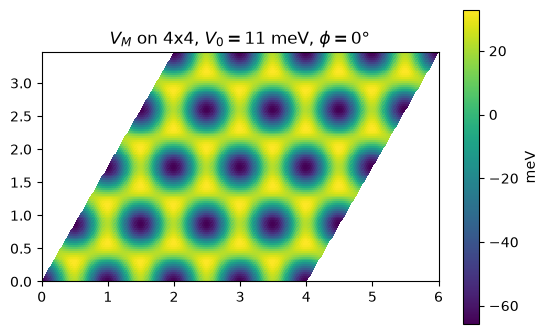

In [ ]:
from moire_mpnqs.physics import moire_potentials

V0 = 11.0                                                     # meV point V11_z0

def cell_grid(L, n_per_cell=40):
    # bin centres over the supercell (fractional coordinates -> cartesian)
    n = n_per_cell * L.M1
    f = (np.arange(n) + 0.5) / n
    F1, F2 = np.meshgrid(f, f, indexing="ij")
    F = np.stack((F1, F2), -1)
    return F @ L.supercell                                    # (n, n, 2)

R = cell_grid(lat4, 30)
Vm = np.asarray(moire_potentials(R.reshape(-1, 2), lat4, V0)).reshape(R.shape[:2])
pc = plt.pcolormesh(R[..., 0], R[..., 1], Vm, shading="nearest", rasterized=True)
plt.gca().set_aspect("equal")  # Membuat skala x dan y 1:1
plt.title(rf"$V_M$ on 4x4, $V_0={V0:g}$ meV, $\phi={np.degrees(0):.0f}°$")
plt.colorbar(pc, shrink=0.85).set_label("meV")
# plt.tight_layout()
print("min V_M =", float(moire_potentials(jnp.zeros((1, 2)), lat, V0)[0]), "meV  (= -6 V0 at the sites)")


## 4. Message-passing Neural Quantum States

In [22]:
model = dict(
    orbital_type="bloch_pw",       # multi-band plane-wave Bloch orbitals
    embedding_dim=16,         # dim of h_i and h_ij
    intermediate_dim=32,      # MLP hidden width (paper: 64)
    num_intermediate=1,
    attention_dim=16,
    n_interactions=2,         # message-passing layers (paper: 3)
    activation="tanh",
    jastrow="cusp_nn",        # Kato-cusp Pade + symmetric NN terms (benchmarked best)
)
n_up, n_dn = N // 2, N // 2
rng = np.random.default_rng(1)
X = jnp.asarray(rng.random((3, N, 2)) @ lat.supercell)                  # 3 random configurations (B, N, 2)
print("configs X:", X.shape)

configs X: (3, 8, 2)


In [20]:
from moire_mpnqs.model import MoireMPNN

mpnn = MoireMPNN(lat, n_up, n_dn, h_dim=16, hidden=64, 
                n_layers=3, activation=nnx.tanh, rngs=nnx.Rngs(0))
y = mpnn(X)
print("y = MPNN(X):", y.shape, "  (batch, electrons, features)")

perm = np.arange(N)
perm[[0, 2]] = perm[[2, 0]]                                           # swap two spin-up electrons
y_perm = mpnn(X[:, perm])
print("equivariance |MPNN(PX) - P MPNN(X)| =", float(jnp.max(jnp.abs(y_perm - y[:, perm]))))

y = MPNN(X): (3, 8, 22)   (batch, electrons, features)
equivariance |MPNN(PX) - P MPNN(X)| = 1.3322676295501878e-15


## 5 VMC Optimization

In [23]:
import tempfile

from moire_mpnqs.vmc import build_problem, run

RUN = Path(tempfile.mkdtemp(prefix="mpnqs_walkthrough_"))          # a run directory, like runs/<tag>/
N_ITER = 200
P = build_problem(V0, n_up, n_dn, M=M, n_samples=256, n_chains=32, n_burnin=200, seed=0,
                  model_kwargs=model)
print("run directory:", RUN)
drv = run(P, N_ITER, lr=1e-3, diag_shift=1e-3, clip=0.1, history=RUN / "history.jsonl", print_every=25)

run directory: /var/folders/8v/90w35msj4jlcnrsl289b61g40000gp/T/mpnqs_walkthrough_e908ays1
Automatic SR implementation choice: NTK (n_parameters=37117, n_samples=256)
Automatic SR on_the_fly choice: True
online_statistics: chain_length=8, exponential moving average window: 50, decay=0.840
it     0  E/N=-57.32381 ± 2.62108  var/N=6808.2708  acc=0.43
it    25  E/N=-88.16187 ± 0.29639  var/N=84.2395  acc=0.45
it    50  E/N=-89.49896 ± 0.21112  var/N=81.5213  acc=0.45
it    75  E/N=-89.92145 ± 0.17209  var/N=48.9117  acc=0.46
it   100  E/N=-89.45908 ± 0.27054  var/N=118.1210  acc=0.45
it   125  E/N=-88.93635 ± 0.54107  var/N=230.9952  acc=0.46
it   150  E/N=-89.31669 ± 0.31471  var/N=76.3670  acc=0.45
it   175  E/N=-89.06487 ± 0.34621  var/N=119.9861  acc=0.46
it   199  E/N=-89.62997 ± 0.16619  var/N=39.8185  acc=0.46


last 20 steps: E/N = -89.466 meV, var/N = 81.0 meV^2


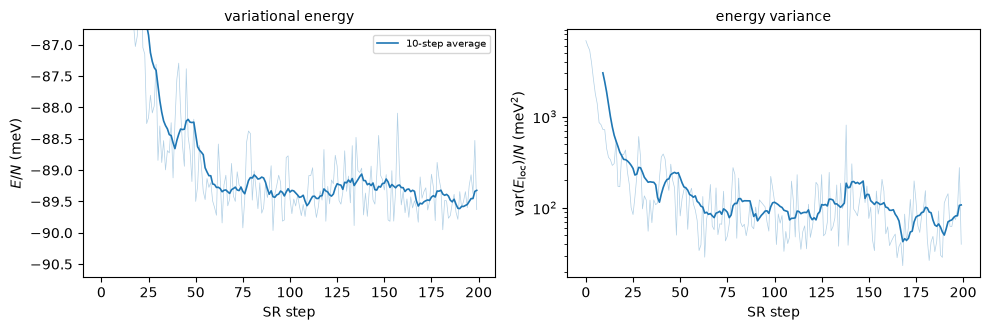

In [26]:
from plotter import load_training, plot_training


it, E_hist, var_hist, _ = load_training(RUN, N)
fig, (ax_e, ax_v) = plt.subplots(1, 2, figsize=(10, 3.4))
plot_training(ax_e, ax_v, it, E_hist, var_hist, None, k=10, prefixes=("", ""))
plt.tight_layout()
print(f"last 20 steps: E/N = {E_hist[-20:].mean():.3f} meV, var/N = {var_hist[-20:].mean():.1f} meV^2")

## 6 Final Energy Evaluation

In [27]:
from moire_mpnqs.vmc import evaluate

res = evaluate(P, n_samples=2048, n_discard_per_chain=50, chunk_size=256, thin=2)
for k in ("E", "T", "V_moire", "V_ee"):
    r_ = res[k]
    print(f"{k:8s}/N = {r_['mean']:+9.3f} +- {r_['err']:.3f} meV   var/N = {r_['var']:8.3f}   "
            f"R_hat = {r_['R_hat']:.3f}")
print(f"acceptance = {res['acceptance']:.2f}")

E       /N =   -89.228 +- 0.170 meV   var/N =  101.354   R_hat = 1.062
T       /N =   +16.096 +- 0.266 meV   var/N =  595.596   R_hat = 1.019
V_moire /N =   -28.283 +- 0.305 meV   var/N =  402.985   R_hat = 1.037
V_ee    /N =   -77.041 +- 0.209 meV   var/N =  554.310   R_hat = 1.016
acceptance = 0.46


## 7 Electron Density Map
$$n(\mathbf{r})=\langle\sum_i\delta(\mathbf{r}-\mathbf{r}_i)\rangle$$

16384 samples | mean n = 2.3094 a_M^-2 | max n = 8.2994 a_M^-2 | integral = 8.000 (expected 8)


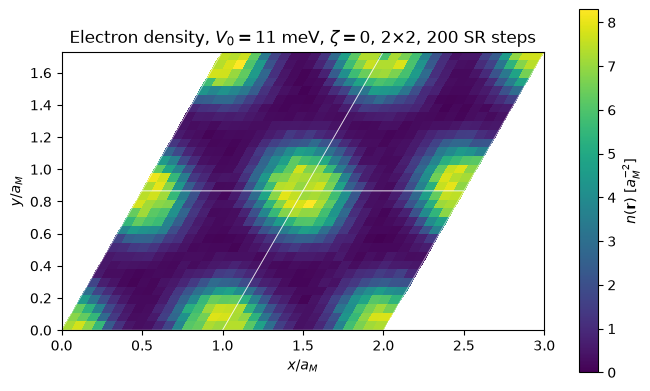

In [31]:
from moire_mpnqs.observables import measure, save_observables
from plot_observable import plot_density

observable = measure(
    P, n_up=n_up, n_dn=n_dn,
    n_batches=16, n_samples=1024, n_discard_per_chain=20, bins_per_cell=16,
)
save_observables(observable, RUN)

m = observable["meta"]
density = observable["arrays"]["n"]
print(
    f"{m['n_samples']} samples | mean n = {m['mean_density']:.4f} a_M^-2 | "
    f"max n = {density.max():.4f} a_M^-2 | "
    f"integral = {m['integrated_density']:.3f} (expected {m['N']})"
)

fig, ax = plt.subplots(figsize=(6.4, 3.8), layout="constrained")
mesh = plot_density(observable, key="n", ax=ax)
fig.colorbar(mesh, ax=ax, label=r"$n(\mathbf{r})$ [$a_M^{-2}$]")
ax.set_title(rf"Electron density, $V_0={V0:g}$ meV, $\zeta=0$, {M}×{M}, {N_ITER} SR steps")
plt.show()

- Units: Following Paper A Fig. 4, the map is shown in units of $a^{-2}$, where $a$ is the mean inter-electron spacing (0.371 $a_M$ at ν = 2).
- At V0 = 11 meV, ζ = 0, each moiré minimum hosts one two-electron molecule (the s-wave molecular insulator).